# 残差网络：让特征有一条直达通路

目标：在同一个 MNIST 任务中理解残差连接。残差块将变换后的特征与另一条分支相加，让梯度和信息有更直接的通路。

这是用于学习的小残差网络，不是完整 ResNet-20。沿用 LeNet 的数据与训练结构，只替换模型。

从项目根目录运行。`device` 可换为 `"cpu"` 或 `"cuda"`；不固定随机种子。

In [2]:
from qutai import Stream, nn, visualization
from examples.data.data import load_mnist

device = "apple"

## 1. 看数据

继续使用 MNIST。输入、批次数和可视化都与 LeNet 相同，可以集中比较两种网络的结构。

一批图像的形状： (32, 1, 28, 28)



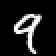
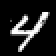
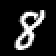
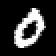

In [3]:
train_inputs, train_targets = load_mnist("train")
test_inputs, test_targets = load_mnist("test")
data = Stream(train_inputs, train_targets, batch_size=32, limit=256, device=device)
inputs, targets = next(iter(data))
print("一批图像的形状：", inputs.shape)
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1), scale=2) for image in inputs[:4]], labels=targets[:4], title="真实 MNIST 与正确标签")

## 2. 搭模型

第一块保持通道数和尺寸；第二块增加通道并将长宽减半，内部会用投影分支对齐形状。最后展平为 8×14×14 个数，再分类。BatchNorm 根据当前训练批次估计归一化统计量。

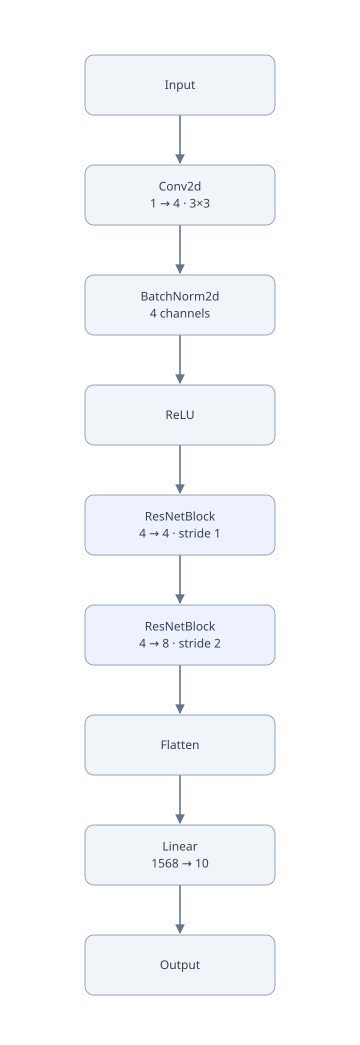

In [4]:
model = nn.Model([
    nn.Conv2d(1, 4, 3, padding=1, bias=False), nn.BatchNorm2d(4), nn.ReLU(),
    nn.ResNetBlock(4, 4),
    nn.ResNetBlock(4, 8, stride=2),
    nn.Flatten(), nn.Linear(8 * 14 * 14, 10),
], device=device)
optimizer = nn.AdamW(model, learning_rate=0.003)
loss_function = nn.CrossEntropy()

visualization.Network(model)

## 3. 训练

训练循环不需要知道模型里存在分支：前向由层负责组织，`backward()` 会沿两条分支传播并汇总梯度。

In [5]:
epochs = 50
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.6f}")

epoch 1/50  loss 1.070798
epoch 2/50  loss 0.330798
epoch 3/50  loss 0.123831
epoch 4/50  loss 0.049191
epoch 5/50  loss 0.017028
epoch 6/50  loss 0.012752
epoch 7/50  loss 0.007307
epoch 8/50  loss 0.007585
epoch 9/50  loss 0.006559
epoch 10/50  loss 0.004267
epoch 11/50  loss 0.004875
epoch 12/50  loss 0.003326
epoch 13/50  loss 0.003029
epoch 14/50  loss 0.003280
epoch 15/50  loss 0.002306
epoch 16/50  loss 0.002443
epoch 17/50  loss 0.002406
epoch 18/50  loss 0.001955
epoch 19/50  loss 0.001653
epoch 20/50  loss 0.001942
epoch 21/50  loss 0.001757
epoch 22/50  loss 0.001481
epoch 23/50  loss 0.000933
epoch 24/50  loss 0.001617
epoch 25/50  loss 0.001090
epoch 26/50  loss 0.001398
epoch 27/50  loss 0.000782
epoch 28/50  loss 0.000971
epoch 29/50  loss 0.000923
epoch 30/50  loss 0.000981
epoch 31/50  loss 0.000953
epoch 32/50  loss 0.000770
epoch 33/50  loss 0.000818
epoch 34/50  loss 0.000937
epoch 35/50  loss 0.000991
epoch 36/50  loss 0.000923
epoch 37/50  loss 0.000427
epoch 38/5

## 4. 看结果

预测使用 `train=False`，BatchNorm 会采用训练中积累的统计量。短实验用于理解残差块和批次训练，不能据此比较完整 ResNet 与 LeNet 的性能。

这 64 张测试图的准确率：76.6%



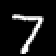
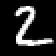
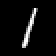
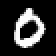

In [6]:
inputs, targets = next(iter(Stream(test_inputs, test_targets, batch_size=64, shuffle=False, device=device)))
predictions = model(inputs, train=False).argmax(axis=-1)
correct = sum(prediction == target for prediction, target in zip(predictions, targets))
print(f"这 64 张测试图的准确率：{correct / len(targets):.1%}")
visualization.ImageCombine([visualization.Image.from_tensor(image, value_range=(0, 1), scale=2) for image in inputs[:4]], labels=[f"正确 {target} / 预测 {prediction}" for target, prediction in zip(targets[:4], predictions[:4])])